# 06. Supplier Offers, Margins & Inventory Tracking
**Phase 2: Exploratory Data Analysis**  
**Datasets:** `cleaned_supplier_offers`, `cleaned_inventory_availability` (Currency: INR ₹)

Evaluates supplier procurement costs, gross profit margins, inventory capacity utilization, and snapshot cardinality guardrails.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
from IPython.display import Image, display
from eda.data_loader import load_dataset
from eda.kpi_calculations import compute_supplier_kpis, compute_inventory_kpis
from eda.snapshot_analysis import validate_snapshot_cardinality, get_latest_inventory_snapshots
from eda.visualization import plot_inventory_utilization_distribution, plot_supplier_markup_and_margin_by_supplier


## 1. Supplier Procurement KPIs & Margins


In [2]:
supplier_df = load_dataset("supplier_offers")
supplier_kpis = compute_supplier_kpis(supplier_df)
print(f"Total Offers: {supplier_kpis['total_offers']:,}")
print(f"Average Wholesale Cost: ₹{supplier_kpis['avg_purchase_cost_inr']:,.2f}")
print(f"Average Retail Selling: ₹{supplier_kpis['avg_selling_price_inr']:,.2f}")
print(f"Average Margin: {supplier_kpis['avg_margin_pct']:.2f}%")
print(f"Negative Margin Offers: {supplier_kpis['negative_margin_offers']} ({supplier_kpis['negative_margin_pct']:.2f}%)")


Total Offers: 5,000
Average Wholesale Cost: ₹8,549.93
Average Retail Selling: ₹11,064.99
Average Margin: 22.54%
Negative Margin Offers: 0 (0.00%)


## 2. Inventory Utilization & Snapshot Deduplication


In [3]:
inventory_df = load_dataset("inventory_availability")
card = validate_snapshot_cardinality(inventory_df)
print("Snapshot Validation:", card["cardinality_guideline"])

inv_kpis = compute_inventory_kpis(inventory_df, deduplicate_snapshots=True)
print(f"Unique Inventory Units: {inv_kpis['distinct_inventory_items']:,}")
print(f"Total Physical Capacity: {inv_kpis['total_capacity']:,.0f}")
print(f"Total Booked Units: {inv_kpis['total_booked_units']:,.0f}")
print(f"Capacity Utilization Rate: {inv_kpis['overall_utilization_rate_pct']:.2f}%")
print(f"Stockout Frequency: {inv_kpis['stockout_frequency_pct']:.2f}%")


Snapshot Validation: WARNING: Dataset contains multiple temporal snapshots. Never sum capacity or available units across all rows directly. Filter to latest snapshot or group by snapshot_date.
Unique Inventory Units: 157
Total Physical Capacity: 197,398
Total Booked Units: 154,790
Capacity Utilization Rate: 78.42%
Stockout Frequency: 14.00%


## 3. Inventory Utilization & Supplier Margin Figures


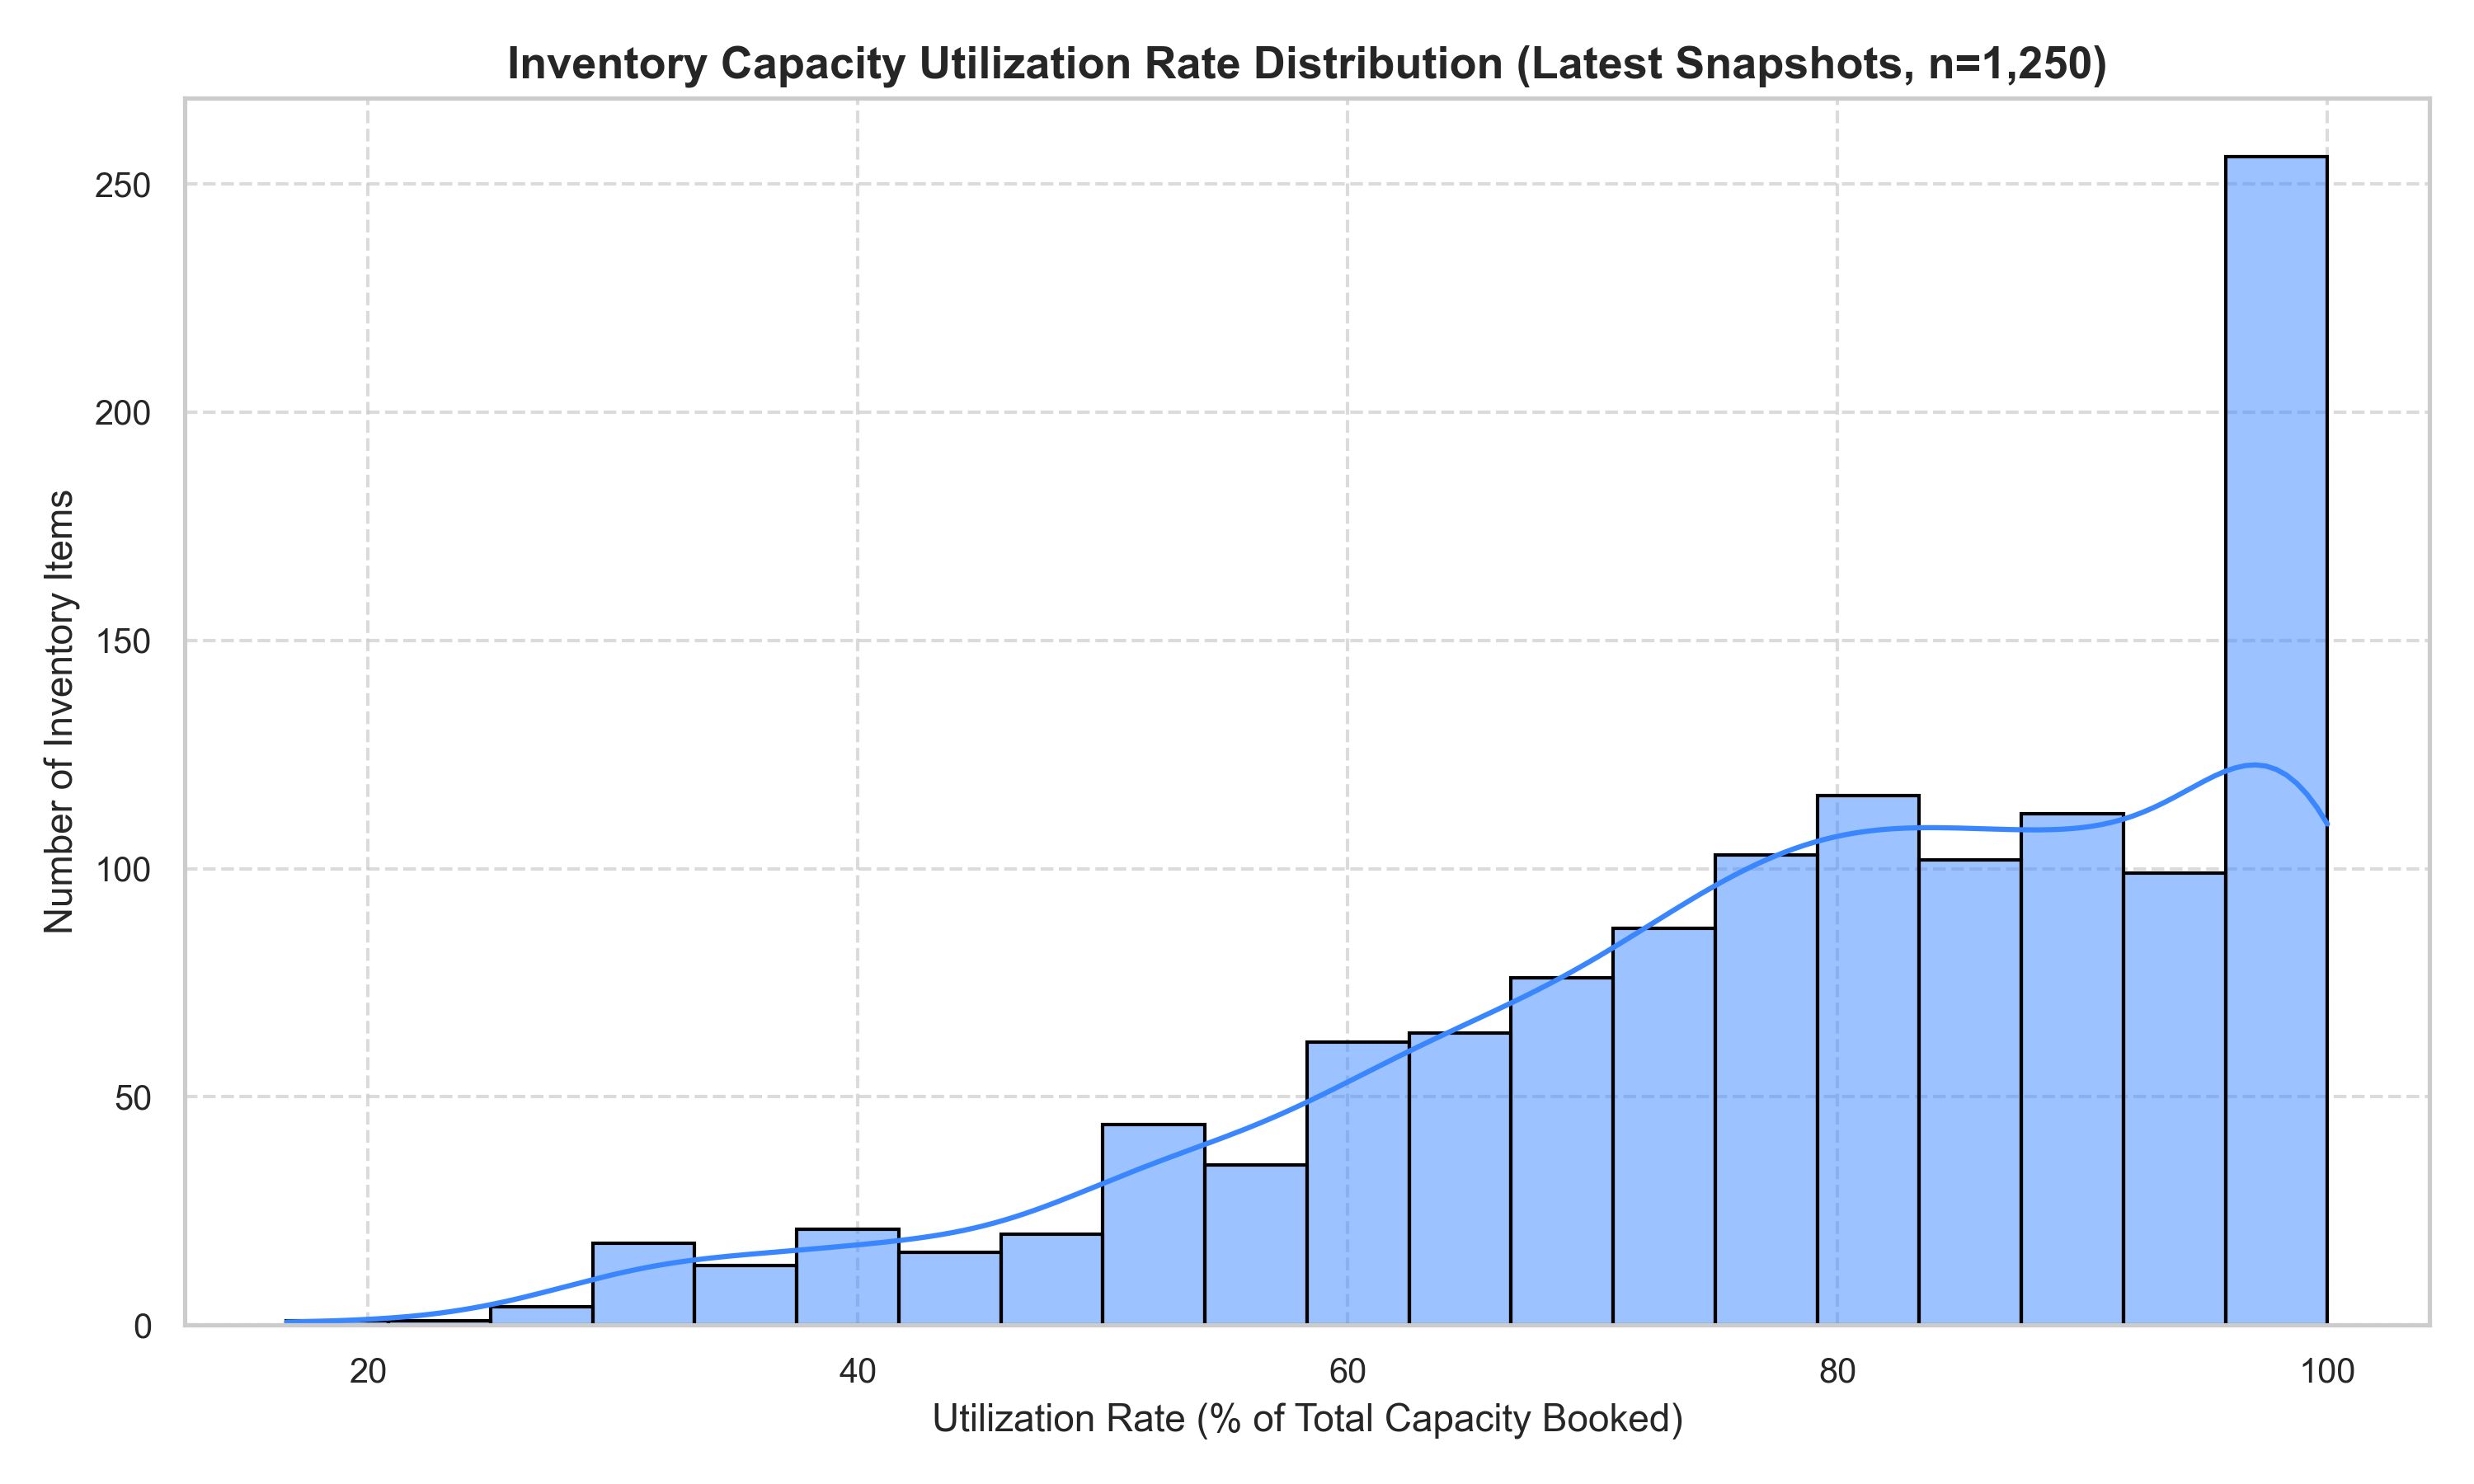

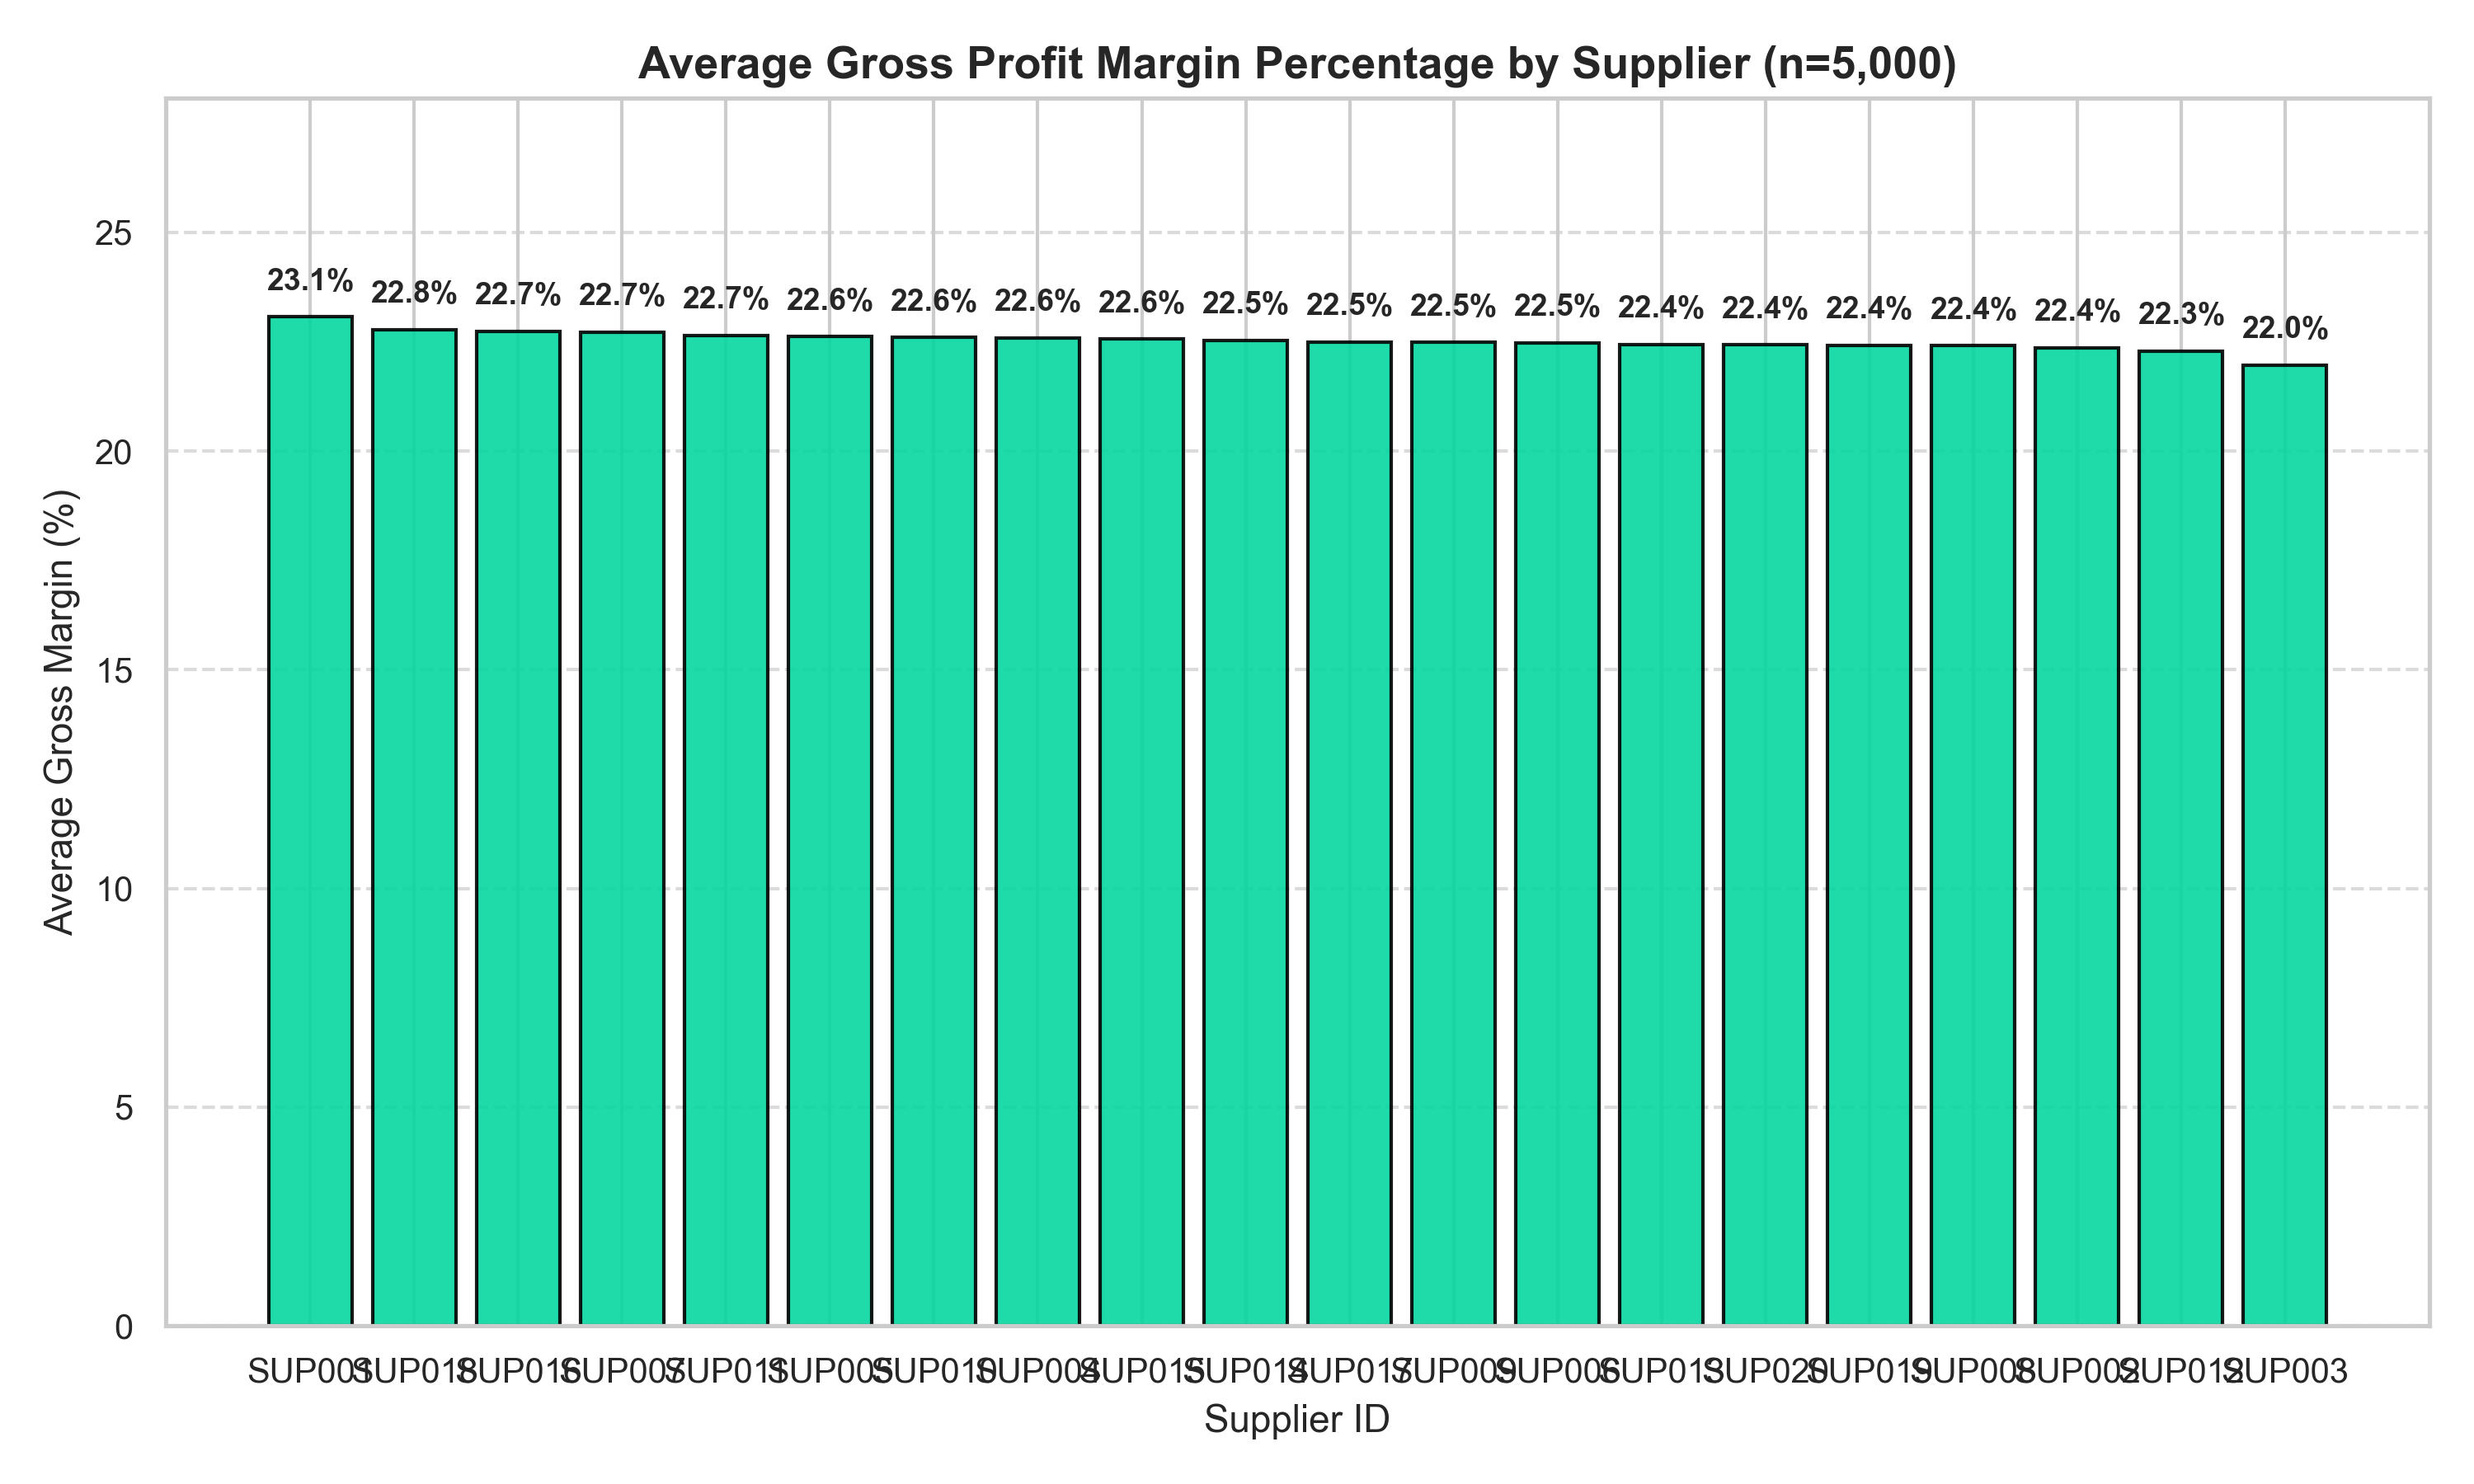

In [4]:
fig9_path = plot_inventory_utilization_distribution(inventory_df)
display(Image(filename=str(fig9_path)))

fig10_path = plot_supplier_markup_and_margin_by_supplier(supplier_df)
display(Image(filename=str(fig10_path)))
